# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 05: Iris Quality Assessment

### Objective

This notebook computes a per-image quality score for every enhanced iris texture produced in Notebook 04, and separates the dataset into usable and unusable images before the few-shot dataset is constructed.

The notebook must:

1. Read the enhancement metadata produced by Notebook 04, and the segmentation metadata produced by Notebook 02 (needed for reflection statistics).
2. Calculate, for every successfully enhanced image: **blur score**, **contrast**, **illumination**, **occlusion**, **reflection percentage**, and **focus**.
3. Combine these into a single **Quality Score in the range 0-100**.
4. Filter out poor-quality images using a configurable threshold.
5. Save `quality_scores.csv`, and copy each successfully processed image into `good_images/` or `bad_images/` according to the filter decision.

### Important boundary of this notebook

This notebook performs **quality scoring and filtering only**.

It does **not** perform:

- few-shot support/query split creation (Notebook 06),
- feature extraction or iris code encoding,
- recognition model training,
- any further image enhancement (that belongs to Notebook 04; a low quality score here is a *signal*, not something this notebook tries to fix).

### Why this stage exists

The few-shot dataset built in Notebook 06 depends heavily on which images are treated as valid samples per identity: with only 1-5 support images per identity, a single badly blurred or heavily occluded image can dominate a support set. This notebook exists to catch that *before* few-shot splits are created, rather than after, when a bad sample would silently bias every downstream experiment.


## 1. Research rationale

Six factors are computed per image, matching standard iris/biometric image-quality literature:

- **Blur score** — variance of the Laplacian. A sharp image has many strong edges, so the Laplacian (second derivative) has high variance; a blurred image has a nearly flat Laplacian response, so the variance collapses toward zero.
- **Focus score** — Tenengrad measure: the mean squared Sobel gradient magnitude. This is a complementary sharpness measure to blur score (gradient energy rather than second-derivative variance), and the two are combined rather than treated as duplicates, since they respond differently to different degradation types (e.g. motion blur vs. out-of-focus blur).
- **Contrast** — standard deviation of intensity over the non-occluded pixels of the enhanced texture. Low contrast indicates the enhancement pipeline had little genuine texture to work with (e.g. very poor original acquisition).
- **Illumination** — mean intensity of the non-occluded pixels, scored by closeness to mid-gray (128). Both very dark and very bright normalized textures indicate an illumination problem in the original capture that enhancement could not fully correct.
- **Occlusion** — the fraction of the normalized texture flagged as noise by Notebook 03 (eyelid, eyelash, reflection, or outside the usable iris annulus). This is read directly from the normalized noise mask rather than re-derived, since Notebook 03 already computed it precisely from the segmentation boundaries.
- **Reflection percentage** — the specular-reflection area as a fraction of the total iris area, taken from Notebook 02's segmentation statistics (`reflection_area_px / iris_area_px`). This is a property of the original acquisition and does not change during normalization or enhancement, so it is carried forward rather than recomputed.

### Combining into one score

Each raw metric is on a different, non-comparable scale (pixel-intensity variance vs. a 0-1 fraction, for example). Two normalization strategies are used depending on whether a metric already has a natural bound:

- **Naturally bounded metrics** (occlusion fraction, illumination distance from mid-gray, reflection fraction) are mapped to `[0, 1]` with a simple, fixed formula.
- **Unbounded metrics** (blur score, focus score, contrast) are normalized using the **5th/95th percentile of that metric across the whole processed dataset**, clipped to `[0, 1]`. This is a population-relative normalization: instead of guessing a fixed "good" threshold for these datasets in isolation, each image's score is judged against the sharpness/contrast actually observed in this run. This is a two-pass computation: pass 1 computes every raw metric for every image, pass 2 derives the percentiles and the final composite score.

The final `quality_score` is a weighted sum of the five normalized components, scaled to `0-100`. Weights favor sharpness (blur + focus) and occlusion, since a blurred or heavily occluded iris texture is far more damaging to recognition than a slightly off-center illumination.


In [1]:
# ============================================================
# 2. Imports
# ============================================================

from pathlib import Path
import json
import math
import random
import shutil
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK02_RESULTS_DIR = PROJECT_ROOT / "results" / "iris_segmentation"
SEGMENTATION_METADATA_PATH = NOTEBOOK02_RESULTS_DIR / "segmentation_metadata.csv"

NOTEBOOK04_RESULTS_DIR = PROJECT_ROOT / "results" / "image_enhancement"
ENHANCEMENT_METADATA_PATH = NOTEBOOK04_RESULTS_DIR / "enhancement_metadata.csv"

RESULTS_DIR = PROJECT_ROOT / "results" / "iris_quality_assessment"

GOOD_DIR = RESULTS_DIR / "good_images"
BAD_DIR = RESULTS_DIR / "bad_images"
PREVIEW_DIR = RESULTS_DIR / "previews"

GOOD_DIR.mkdir(parents=True, exist_ok=True)
BAD_DIR.mkdir(parents=True, exist_ok=True)
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Notebook 02 segmentation metadata:", SEGMENTATION_METADATA_PATH)
print("Notebook 04 enhancement metadata:", ENHANCEMENT_METADATA_PATH)
print("Notebook 05 results:", RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 02 segmentation metadata: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_segmentation\segmentation_metadata.csv
Notebook 04 enhancement metadata: E:\Research\LargeScale_Synthetic_Iris_Generation\results\image_enhancement\enhancement_metadata.csv
Notebook 05 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment


## 4. Load and merge metadata

This notebook needs information from two earlier notebooks:

- **Notebook 04** (`enhancement_metadata.csv`) supplies the enhanced texture path, the Notebook 03 noise mask, and the enhancement success flag. This is the primary table — one row per image that reached the enhancement stage.
- **Notebook 02** (`segmentation_metadata.csv`) supplies `reflection_area_px` and `iris_area_px`, needed for the reflection-percentage metric. Only these two columns are pulled in, joined on `(dataset, identity, eye, filename)`, to avoid duplicating columns already carried forward through Notebooks 03 and 04.

Rows are kept even when the earlier stages failed, so the final accounting in `quality_scores.csv` traces every image from raw capture through to a quality decision (or the stage at which it dropped out).


In [3]:
# ============================================================
# 4. Load and merge metadata
# ============================================================

if not ENHANCEMENT_METADATA_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 04 enhancement metadata was not found at: "
        f"{ENHANCEMENT_METADATA_PATH}\n"
        "Run 04_Image_Enhancement.ipynb first."
    )

if not SEGMENTATION_METADATA_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 02 segmentation metadata was not found at: "
        f"{SEGMENTATION_METADATA_PATH}\n"
        "Run 02_Iris_Segmentation.ipynb first."
    )

enhancement_metadata = pd.read_csv(ENHANCEMENT_METADATA_PATH)
segmentation_metadata = pd.read_csv(SEGMENTATION_METADATA_PATH)

required_enhancement_columns = {
    "dataset",
    "identity",
    "eye",
    "filename",
    "success",
    "enhanced_path",
    "noise_mask_path",
}

missing = required_enhancement_columns.difference(enhancement_metadata.columns)
if missing:
    raise ValueError(
        f"Notebook 04 metadata is missing required columns: {sorted(missing)}"
    )

required_segmentation_columns = {
    "dataset",
    "identity",
    "eye",
    "filename",
    "reflection_area_px",
    "iris_area_px",
}

missing = required_segmentation_columns.difference(segmentation_metadata.columns)
if missing:
    raise ValueError(
        f"Notebook 02 metadata is missing required columns: {sorted(missing)}"
    )

merge_keys = ["dataset", "identity", "eye", "filename"]

quality_input = enhancement_metadata.merge(
    segmentation_metadata[merge_keys + ["reflection_area_px", "iris_area_px"]],
    on=merge_keys,
    how="left",
)

print("Enhancement metadata shape:", enhancement_metadata.shape)
print("Merged quality-input shape:", quality_input.shape)
print(
    "Successful enhancements available for quality scoring:",
    int(quality_input["success"].sum()),
    "/",
    len(quality_input),
)

display(quality_input.head())

Enhancement metadata shape: (22180, 15)
Merged quality-input shape: (22180, 17)
Successful enhancements available for quality scoring: 22176 / 22180


,dataset,identity,eye,filename,normalized_path,noise_mask_path,valid_fraction,success,reason,enhancement_pipeline,mean_intensity_before,std_intensity_before,mean_intensity_after,std_intensity_after,enhanced_path,reflection_area_px,iris_area_px
0,CASIA-Iris-Thousand,0,L,S5000L00.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,0.904480,True,NaN,denoise -> contrast_stretch -> clahe -> sharpen,74.536163,16.933165,127.004608,56.664296,E:\Research\LargeScale_Synthetic_Iris_Generati...,0,28917.0
1,CASIA-Iris-Thousand,0,L,S5000L01.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,0.891266,True,NaN,denoise -> contrast_stretch -> clahe -> sharpen,75.693451,14.913017,121.324768,54.655639,E:\Research\LargeScale_Synthetic_Iris_Generati...,0,28917.0
2,CASIA-Iris-Thousand,0,L,S5000L02.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,0.921600,True,NaN,denoise -> contrast_stretch -> clahe -> sharpen,87.279175,45.367603,105.241547,52.605249,E:\Research\LargeScale_Synthetic_Iris_Generati...,108,28217.0
3,CASIA-Iris-Thousand,0,L,S5000L03.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,0.891998,True,NaN,denoise -> contrast_stretch -> clahe -> sharpen,75.932404,43.433514,68.422058,56.487600,E:\Research\LargeScale_Synthetic_Iris_Generati...,192,69729.0
4,CASIA-Iris-Thousand,0,L,S5000L04.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,0.320435,True,NaN,denoise -> contrast_stretch -> clahe -> sharpen,27.867523,41.516592,69.586243,97.477351,E:\Research\LargeScale_Synthetic_Iris_Generati...,392,61465.0


## 5. Configuration

`QUALITY_THRESHOLD` is the cutoff on the final 0-100 score below which an image is filtered out. The component weights must sum to 1.0 so the final score stays on a 0-100 scale.


In [4]:
# ============================================================
# 5. Configuration
# ============================================================

MAX_IMAGES_PER_DATASET = None   # e.g. 20 for an initial test; None = all
SAVE_PREVIEWS = True
PREVIEW_COUNT_PER_DATASET = 6

# Percentile bounds used to normalize unbounded metrics (blur, focus, contrast)
# across the processed dataset.
NORMALIZATION_LOW_PERCENTILE = 5.0
NORMALIZATION_HIGH_PERCENTILE = 95.0

# Reflection fraction at or above this value is treated as maximally bad
# (reflection_quality saturates at 0).
REFLECTION_FRACTION_CAP = 0.05   # 5% of the iris area

# Composite quality score weights. Must sum to 1.0.
WEIGHT_SHARPNESS = 0.30    # average of blur_norm and focus_norm
WEIGHT_CONTRAST = 0.20
WEIGHT_ILLUMINATION = 0.15
WEIGHT_OCCLUSION = 0.20
WEIGHT_REFLECTION = 0.15

assert abs(
    (WEIGHT_SHARPNESS + WEIGHT_CONTRAST + WEIGHT_ILLUMINATION
     + WEIGHT_OCCLUSION + WEIGHT_REFLECTION)
    - 1.0
) < 1e-6, "Quality score weights must sum to 1.0"

# Final 0-100 score at or above which an image is accepted.
QUALITY_THRESHOLD = 50.0

print("Configuration loaded.")
print(f"Quality threshold: {QUALITY_THRESHOLD}")

Configuration loaded.
Quality threshold: 50.0


## 6. Utility functions

`safe_read_gray` and `safe_read_mask` reuse the same conventions established in Notebooks 02-04.


In [5]:
# ============================================================
# 6. Utility functions
# ============================================================

def safe_read_gray(path):
    '''Read an image as uint8 grayscale.'''
    path = Path(path)
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Unable to read image: {path}")

    if image.dtype != np.uint8:
        image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    return image


def safe_read_mask(path, shape):
    '''Read a mask saved by an earlier notebook. Falls back to an all-zero mask.'''
    if path is None or (isinstance(path, float) and np.isnan(path)):
        return np.zeros(shape, dtype=np.uint8)

    path = Path(str(path))

    if not path.exists():
        return np.zeros(shape, dtype=np.uint8)

    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        return np.zeros(shape, dtype=np.uint8)

    if mask.shape != shape:
        mask = cv2.resize(
            mask,
            (shape[1], shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )

    return mask

## 7. Individual quality metrics

Each metric is implemented as a small, independently testable function, matching the six factors requested: blur, contrast, illumination, occlusion, reflection percentage, and focus.


In [6]:
# ============================================================
# 7. Individual quality metrics
# ============================================================

def compute_blur_score(gray):
    '''Variance of the Laplacian. Higher = sharper.'''
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())


def compute_focus_score(gray):
    '''Tenengrad measure: mean squared Sobel gradient magnitude. Higher = sharper.'''
    grad_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    grad_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    return float(np.mean(grad_x ** 2 + grad_y ** 2))


def compute_contrast(gray, valid_mask=None):
    '''Standard deviation of intensity over valid (non-occluded) pixels.'''
    if valid_mask is not None and valid_mask.any():
        sample = gray[valid_mask]
    else:
        sample = gray.reshape(-1)
    return float(sample.std())


def compute_illumination(gray, valid_mask=None):
    '''Mean intensity over valid (non-occluded) pixels.'''
    if valid_mask is not None and valid_mask.any():
        sample = gray[valid_mask]
    else:
        sample = gray.reshape(-1)
    return float(sample.mean())


def compute_occlusion_fraction(noise_mask):
    '''Fraction of the normalized texture flagged as noise/occlusion.'''
    return float((noise_mask > 0).mean())


def compute_reflection_fraction(reflection_area_px, iris_area_px):
    '''Reflection area as a fraction of total iris area, from Notebook 02 stats.'''
    if pd.isna(reflection_area_px) or pd.isna(iris_area_px) or iris_area_px <= 0:
        return np.nan
    return float(reflection_area_px / iris_area_px)

## 8. Single-image test

Before running the full dataset, every metric is computed once on a single enhanced image and printed, so any obviously wrong value (a negative fraction, a NaN that should be a number) is caught early.


In [7]:
# ============================================================
# 8. Single-image test
# ============================================================

successful_rows = quality_input[quality_input["success"] == True]

if len(successful_rows) == 0:
    raise RuntimeError(
        "No successful enhancements were found in the Notebook 04 metadata. "
        "Run 04_Image_Enhancement.ipynb with a configuration that produces "
        "at least some successful enhancements before continuing."
    )

sample_row = successful_rows.iloc[0]

sample_enhanced = safe_read_gray(sample_row["enhanced_path"])
sample_noise_mask = safe_read_mask(sample_row["noise_mask_path"], sample_enhanced.shape)
sample_valid_mask = sample_noise_mask == 0

sample_metrics = {
    "blur_score": compute_blur_score(sample_enhanced),
    "focus_score": compute_focus_score(sample_enhanced),
    "contrast": compute_contrast(sample_enhanced, sample_valid_mask),
    "illumination": compute_illumination(sample_enhanced, sample_valid_mask),
    "occlusion_fraction": compute_occlusion_fraction(sample_noise_mask),
    "reflection_fraction": compute_reflection_fraction(
        sample_row["reflection_area_px"], sample_row["iris_area_px"]
    ),
}

print("Sample:", sample_row["enhanced_path"])
for key, value in sample_metrics.items():
    print(f"{key}: {value}")

Sample: E:\Research\LargeScale_Synthetic_Iris_Generation\results\image_enhancement\enhanced\CASIA-Iris-Thousand\0\L\S5000L00_enhanced.png
blur_score: 703.84165047016
focus_score: 14024.480834960938
contrast: 52.12531522530852
illumination: 130.67680005398475
occlusion_fraction: 0.09552001953125
reflection_fraction: 0.0


## 9. Process the datasets

Every row from Notebook 04 is carried forward, including rows that already failed at an earlier stage. Those rows are recorded with `reason = "enhancement_failed"` and receive no quality score, since there is no enhanced image to score.


In [8]:
# ============================================================
# 9. Select rows to process
# ============================================================

rows_to_process = []

for dataset_name, df in quality_input.groupby("dataset", dropna=False):
    df = df.copy()

    if MAX_IMAGES_PER_DATASET is not None:
        df = df.sample(
            n=min(MAX_IMAGES_PER_DATASET, len(df)),
            random_state=RANDOM_SEED,
        )

    rows_to_process.append(df)

processing_metadata = pd.concat(
    rows_to_process,
    ignore_index=True,
)

print("Rows selected for quality assessment stage:", len(processing_metadata))
display(processing_metadata["dataset"].value_counts())

Rows selected for quality assessment stage: 22180


dataset
CASIA-Iris-Thousand    20000
IITD                    2180
Name: count, dtype: int64

## 10. Pass 1: compute raw metrics

This pass only computes the six raw, unnormalized metrics for every image. Normalization needs the full distribution of blur/focus/contrast across the dataset, so it cannot happen until every row in this pass is done.


In [9]:
# ============================================================
# 10. Pass 1: compute raw metrics for every image
# ============================================================

records = []

total = len(processing_metadata)

for idx, row in processing_metadata.iterrows():

    record = {
        "dataset": row["dataset"],
        "identity": row["identity"],
        "eye": row["eye"],
        "filename": row["filename"],
        "enhanced_path": row.get("enhanced_path"),
        "noise_mask_path": row.get("noise_mask_path"),
        "success": False,
        "reason": None,
        "blur_score": np.nan,
        "focus_score": np.nan,
        "contrast": np.nan,
        "illumination": np.nan,
        "occlusion_fraction": np.nan,
        "reflection_fraction": np.nan,
        "reflection_data_available": False,
    }

    if not bool(row["success"]):
        record["reason"] = "enhancement_failed"
        records.append(record)
        continue

    try:
        enhanced = safe_read_gray(row["enhanced_path"])
        noise_mask = safe_read_mask(row["noise_mask_path"], enhanced.shape)
        valid_mask = noise_mask == 0

        reflection_fraction = compute_reflection_fraction(
            row["reflection_area_px"], row["iris_area_px"]
        )

        record["success"] = True
        record["blur_score"] = compute_blur_score(enhanced)
        record["focus_score"] = compute_focus_score(enhanced)
        record["contrast"] = compute_contrast(enhanced, valid_mask)
        record["illumination"] = compute_illumination(enhanced, valid_mask)
        record["occlusion_fraction"] = compute_occlusion_fraction(noise_mask)
        record["reflection_fraction"] = reflection_fraction
        record["reflection_data_available"] = not pd.isna(reflection_fraction)

    except Exception as e:
        record["success"] = False
        record["reason"] = f"exception: {e}"

    records.append(record)

    if (idx + 1) % 200 == 0 or (idx + 1) == total:
        print(f"Processed {idx + 1} / {total} images")

raw_metrics = pd.DataFrame(records)

print("\nPass 1 complete.")
print("Successful metric computations:", int(raw_metrics["success"].sum()), "/", len(raw_metrics))

Processed 200 / 22180 images
Processed 400 / 22180 images
Processed 600 / 22180 images
Processed 800 / 22180 images
Processed 1000 / 22180 images
Processed 1200 / 22180 images
Processed 1400 / 22180 images
Processed 1600 / 22180 images
Processed 1800 / 22180 images
Processed 2000 / 22180 images
Processed 2200 / 22180 images
Processed 2400 / 22180 images
Processed 2600 / 22180 images
Processed 2800 / 22180 images
Processed 3000 / 22180 images
Processed 3200 / 22180 images
Processed 3400 / 22180 images
Processed 3600 / 22180 images
Processed 3800 / 22180 images
Processed 4000 / 22180 images
Processed 4200 / 22180 images
Processed 4400 / 22180 images
Processed 4600 / 22180 images
Processed 4800 / 22180 images
Processed 5000 / 22180 images
Processed 5200 / 22180 images
Processed 5400 / 22180 images
Processed 5600 / 22180 images
Processed 5800 / 22180 images
Processed 6000 / 22180 images
Processed 6200 / 22180 images
Processed 6400 / 22180 images
Processed 6600 / 22180 images
Processed 6800

## 11. Pass 2: normalize and combine into a Quality Score (0-100)

Blur, focus, and contrast are normalized against their own 5th/95th percentile across the successfully processed images. Occlusion, illumination, and reflection are mapped to `[0, 1]` with fixed formulas since they are already naturally bounded quantities.


In [10]:
# ============================================================
# 11. Pass 2: percentile normalization + composite score
# ============================================================

def percentile_normalize(series, low_pct=NORMALIZATION_LOW_PERCENTILE, high_pct=NORMALIZATION_HIGH_PERCENTILE):
    '''Map a series to [0, 1] using its own low/high percentile, clipped.'''
    valid = series.dropna()

    if len(valid) == 0:
        return pd.Series(np.nan, index=series.index)

    low = np.percentile(valid, low_pct)
    high = np.percentile(valid, high_pct)

    if high <= low:
        return pd.Series(0.5, index=series.index).where(series.notna())

    normalized = (series - low) / (high - low)
    return normalized.clip(0.0, 1.0)


quality_scores = raw_metrics.copy()

successful_mask = quality_scores["success"] == True

blur_norm = percentile_normalize(quality_scores.loc[successful_mask, "blur_score"])
focus_norm = percentile_normalize(quality_scores.loc[successful_mask, "focus_score"])
contrast_norm = percentile_normalize(quality_scores.loc[successful_mask, "contrast"])

quality_scores.loc[successful_mask, "blur_norm"] = blur_norm
quality_scores.loc[successful_mask, "focus_norm"] = focus_norm
quality_scores.loc[successful_mask, "contrast_norm"] = contrast_norm

quality_scores.loc[successful_mask, "sharpness_norm"] = (
    quality_scores.loc[successful_mask, "blur_norm"]
    + quality_scores.loc[successful_mask, "focus_norm"]
) / 2.0

# Illumination: closeness to mid-gray (128), mapped to [0, 1].
quality_scores.loc[successful_mask, "illumination_quality"] = 1.0 - (
    (quality_scores.loc[successful_mask, "illumination"] - 128.0).abs() / 128.0
).clip(0.0, 1.0)

# Occlusion: already a [0, 1] fraction; quality is its complement.
quality_scores.loc[successful_mask, "occlusion_quality"] = (
    1.0 - quality_scores.loc[successful_mask, "occlusion_fraction"]
).clip(0.0, 1.0)

# Reflection: fraction capped at REFLECTION_FRACTION_CAP, missing data -> no penalty.
reflection_fraction = quality_scores.loc[successful_mask, "reflection_fraction"]
reflection_quality = 1.0 - (reflection_fraction / REFLECTION_FRACTION_CAP).clip(0.0, 1.0)
reflection_quality = reflection_quality.fillna(1.0)
quality_scores.loc[successful_mask, "reflection_quality"] = reflection_quality

quality_scores.loc[successful_mask, "quality_score"] = 100.0 * (
    WEIGHT_SHARPNESS * quality_scores.loc[successful_mask, "sharpness_norm"]
    + WEIGHT_CONTRAST * quality_scores.loc[successful_mask, "contrast_norm"]
    + WEIGHT_ILLUMINATION * quality_scores.loc[successful_mask, "illumination_quality"]
    + WEIGHT_OCCLUSION * quality_scores.loc[successful_mask, "occlusion_quality"]
    + WEIGHT_REFLECTION * quality_scores.loc[successful_mask, "reflection_quality"]
)

quality_scores.loc[successful_mask, "accepted"] = (
    quality_scores.loc[successful_mask, "quality_score"] >= QUALITY_THRESHOLD
)
quality_scores["accepted"] = quality_scores["accepted"].fillna(False)

print("Quality scores computed for", int(successful_mask.sum()), "images.")
display(
    quality_scores.loc[
        successful_mask,
        ["dataset", "identity", "eye", "quality_score", "accepted"],
    ].head(10)
)

Quality scores computed for 22176 images.


,dataset,identity,eye,quality_score,accepted
0,CASIA-Iris-Thousand,0,L,53.293298,True
1,CASIA-Iris-Thousand,0,L,50.409375,True
2,CASIA-Iris-Thousand,0,L,46.136239,False
3,CASIA-Iris-Thousand,0,L,47.192185,False
4,CASIA-Iris-Thousand,0,L,36.142275,False
5,CASIA-Iris-Thousand,0,L,48.489618,False
6,CASIA-Iris-Thousand,0,L,49.066444,False
7,CASIA-Iris-Thousand,0,L,54.646106,True
8,CASIA-Iris-Thousand,0,L,52.015192,True
9,CASIA-Iris-Thousand,0,L,52.330140,True


## 12. Build output paths

```text
results/
└── iris_quality_assessment/
    ├── good_images/
    │   ├── CASIA-Iris-Thousand/
    │   └── IITD/
    ├── bad_images/
    │   ├── CASIA-Iris-Thousand/
    │   └── IITD/
    ├── previews/
    └── quality_scores.csv
```


In [11]:
# ============================================================
# 12. Output path helpers
# ============================================================

def dataset_safe_name(dataset):
    return (
        str(dataset)
        .replace("/", "_")
        .replace("\\", "_")
        .replace(" ", "_")
    )


def identity_safe_name(identity):
    if pd.isna(identity):
        return "unknown_identity"
    return str(identity).replace("/", "_").replace("\\", "_")


def eye_safe_name(eye):
    if pd.isna(eye):
        return "UNKNOWN"
    return str(eye).replace("/", "_")


def make_output_path(row, base_dir):
    dataset_name = dataset_safe_name(row["dataset"])
    identity_name = identity_safe_name(row["identity"])
    eye_name = eye_safe_name(row["eye"])
    stem = Path(row["filename"]).stem

    return (
        base_dir /
        dataset_name /
        identity_name /
        eye_name /
        f"{stem}_quality.png"
    )

## 13. Copy images into `good_images/` and `bad_images/`

Only images that reached a quality score (i.e. successfully enhanced images) are copied. Images that already failed at an earlier stage have no enhanced file to copy and remain recorded only in `quality_scores.csv` for full accounting.


In [12]:
# ============================================================
# 13. Copy accepted/rejected images
# ============================================================

for idx, row in quality_scores[quality_scores["success"] == True].iterrows():

    destination_base = GOOD_DIR if row["accepted"] else BAD_DIR
    destination_path = make_output_path(row, destination_base)
    destination_path.parent.mkdir(parents=True, exist_ok=True)

    shutil.copyfile(row["enhanced_path"], destination_path)

    quality_scores.loc[idx, "output_path"] = str(destination_path)

print("Copied accepted images to:", GOOD_DIR)
print("Copied rejected images to:", BAD_DIR)

Copied accepted images to: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment\good_images
Copied rejected images to: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment\bad_images


## 14. Save `quality_scores.csv`

This is the requested hand-off file, saved inside `results/iris_quality_assessment/`.


In [13]:
# ============================================================
# 14. Save quality_scores.csv
# ============================================================

QUALITY_SCORES_PATH = RESULTS_DIR / "quality_scores.csv"

quality_scores.to_csv(
    QUALITY_SCORES_PATH,
    index=False,
)

print("Saved:", QUALITY_SCORES_PATH)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment\quality_scores.csv


## 15. Quality statistics

In [14]:
# ============================================================
# 15. Quality statistics
# ============================================================

total_images = len(quality_scores)
scored = int(quality_scores["success"].sum())
accepted = int(quality_scores["accepted"].sum())

summary = {
    "total_images": total_images,
    "scored_images": scored,
    "accepted_images": accepted,
    "rejected_images": scored - accepted,
    "acceptance_rate_percent": (
        100 * accepted / scored
        if scored else 0.0
    ),
    "mean_quality_score": (
        quality_scores.loc[quality_scores["success"], "quality_score"].mean()
    ),
    "median_quality_score": (
        quality_scores.loc[quality_scores["success"], "quality_score"].median()
    ),
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["metric", "value"],
)

display(summary_df)

print("\nFailure/rejection reasons (rows that never reached scoring):")
display(
    quality_scores.loc[
        ~quality_scores["success"],
        "reason"
    ].value_counts(dropna=False)
)

,metric,value
0,total_images,22180.000000
1,scored_images,22176.000000
2,accepted_images,20380.000000
3,rejected_images,1796.000000
4,acceptance_rate_percent,91.901154
5,mean_quality_score,59.566376
6,median_quality_score,58.009571



Failure/rejection reasons (rows that never reached scoring):


reason
enhancement_failed    4
Name: count, dtype: int64

## 16. Dataset-wise quality summary

In [15]:
# ============================================================
# 16. Dataset-wise quality summary
# ============================================================

dataset_quality_summary = (
    quality_scores
    .groupby("dataset")
    .agg(
        total_images=("filename", "count"),
        scored=("success", "sum"),
        accepted=("accepted", "sum"),
        mean_quality_score=("quality_score", "mean"),
        median_quality_score=("quality_score", "median"),
    )
    .reset_index()
)

dataset_quality_summary["acceptance_rate_percent"] = (
    100 *
    dataset_quality_summary["accepted"] /
    dataset_quality_summary["scored"].replace(0, np.nan)
)

display(dataset_quality_summary)

dataset_summary_path = RESULTS_DIR / "quality_summary_by_dataset.csv"

dataset_quality_summary.to_csv(
    dataset_summary_path,
    index=False,
)

print("Saved:", dataset_summary_path)

,dataset,total_images,scored,accepted,mean_quality_score,median_quality_score,acceptance_rate_percent
0,CASIA-Iris-Thousand,20000,20000,18219,57.876946,57.210136,91.095
1,IITD,2180,2176,2161,75.094224,76.086042,99.310662


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment\quality_summary_by_dataset.csv


## 17. Visual quality-control previews

For each dataset, the highest-scoring, a median-scoring, and the lowest-scoring successfully processed image are displayed together with their metric breakdown, so the numeric score can be sanity-checked against what the image actually looks like.


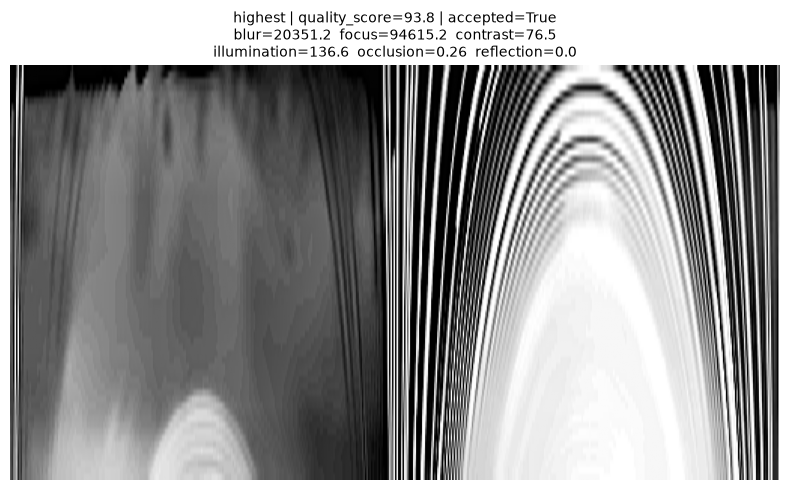

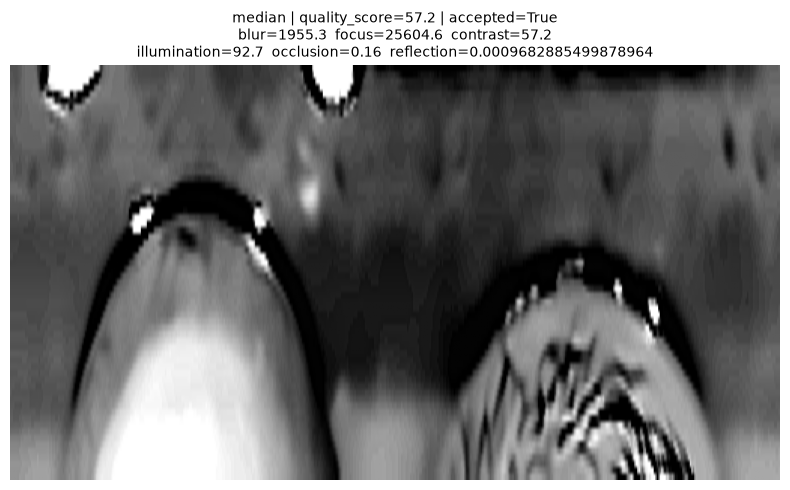

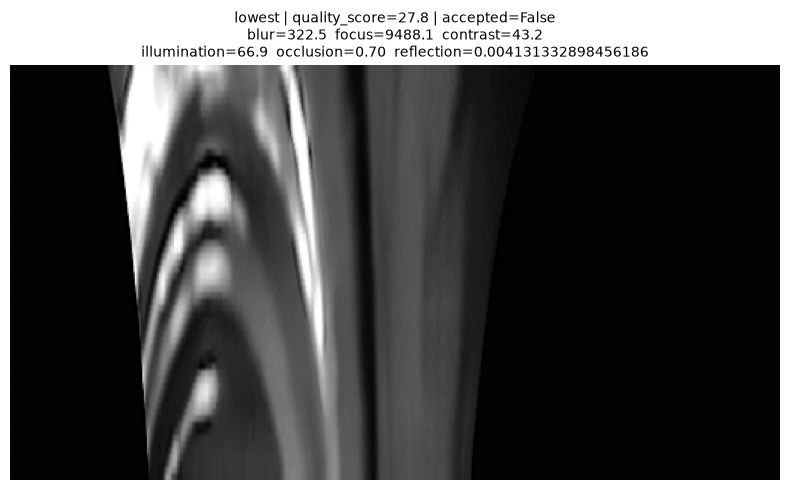

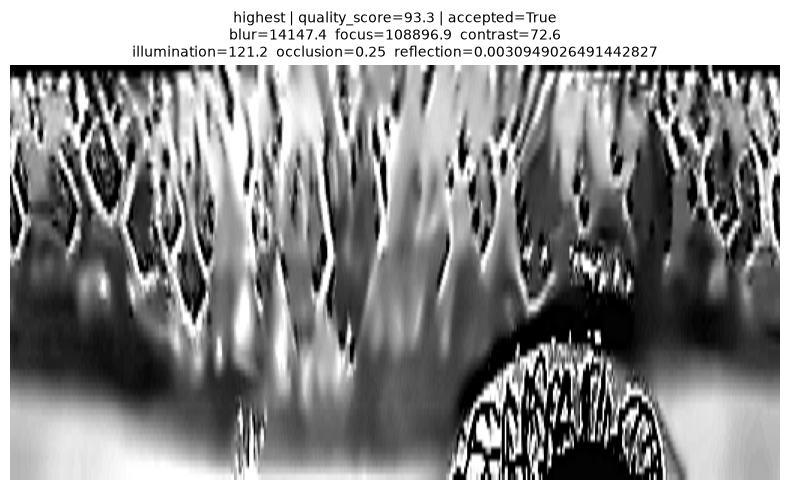

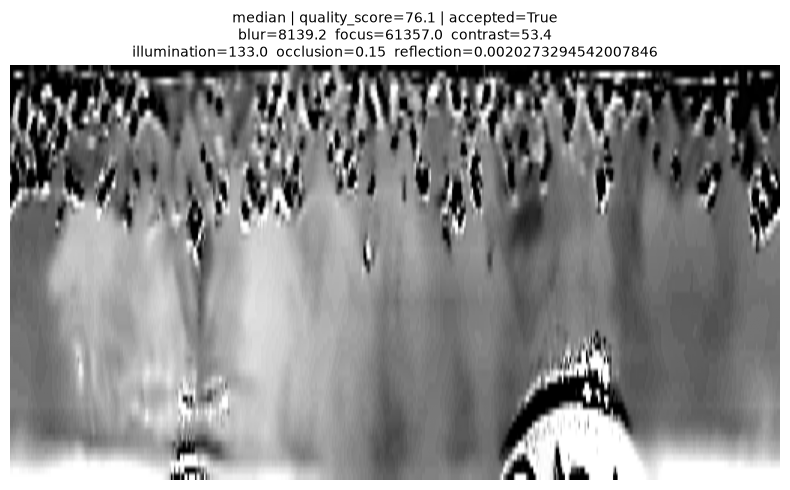

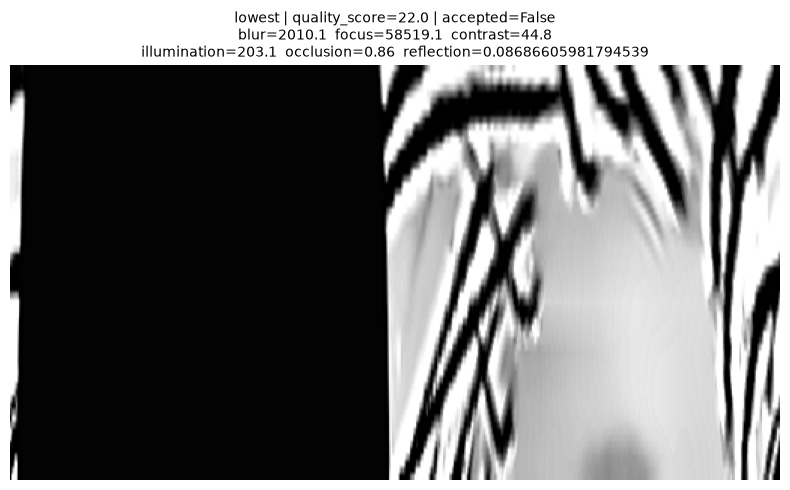

In [16]:
# ============================================================
# 17. Save representative quality previews
# ============================================================

def create_quality_preview(row, rank_label):
    enhanced = cv2.imread(str(row["enhanced_path"]), cv2.IMREAD_GRAYSCALE)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(enhanced, cmap="gray", aspect="auto")
    ax.axis("off")

    info_lines = [
        f"{rank_label} | quality_score={row['quality_score']:.1f} | accepted={bool(row['accepted'])}",
        f"blur={row['blur_score']:.1f}  focus={row['focus_score']:.1f}  contrast={row['contrast']:.1f}",
        f"illumination={row['illumination']:.1f}  occlusion={row['occlusion_fraction']:.2f}  "
        f"reflection={row['reflection_fraction'] if pd.notna(row['reflection_fraction']) else 'n/a'}",
    ]

    ax.set_title("\n".join(info_lines), fontsize=10)

    output_path = (
        PREVIEW_DIR /
        f"{dataset_safe_name(row['dataset'])}_{Path(row['filename']).stem}_{rank_label}.png"
    )

    plt.tight_layout()
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()

    return output_path


if SAVE_PREVIEWS:
    for dataset_name, df in quality_scores.groupby("dataset"):

        scored_df = df[df["success"] == True].sort_values("quality_score")

        if len(scored_df) == 0:
            print(f"No scored images to preview for {dataset_name}")
            continue

        lowest = scored_df.iloc[0]
        highest = scored_df.iloc[-1]
        median = scored_df.iloc[len(scored_df) // 2]

        for row, label in [(highest, "highest"), (median, "median"), (lowest, "lowest")]:
            create_quality_preview(row, label)

## 18. Failure / rejection review table

Images are retained in the metadata whether they failed at an earlier stage, threw an exception during metric computation, or simply scored below the threshold, so the full accounting from raw image to quality decision stays in one place.


In [17]:
# ============================================================
# 18. Failure and rejection review
# ============================================================

not_scored_table = quality_scores[~quality_scores["success"]].copy()

display(
    not_scored_table[
        ["dataset", "identity", "eye", "filename", "reason"]
    ].head(50)
)

rejected_table = quality_scores[
    (quality_scores["success"]) & (~quality_scores["accepted"])
].copy()

display(
    rejected_table[
        ["dataset", "identity", "eye", "filename", "quality_score"]
    ].sort_values("quality_score").head(50)
)

REJECTED_REPORT_PATH = RESULTS_DIR / "quality_rejections.csv"

pd.concat([not_scored_table, rejected_table], ignore_index=True).to_csv(
    REJECTED_REPORT_PATH,
    index=False,
)

print("Saved:", REJECTED_REPORT_PATH)

,dataset,identity,eye,filename,reason
21747,IITD,175,NaN,08_R.bmp,enhancement_failed
22010,IITD,202,NaN,01_L.bmp,enhancement_failed
22011,IITD,202,NaN,02_L.bmp,enhancement_failed
22014,IITD,202,NaN,05_L.bmp,enhancement_failed


,dataset,identity,eye,filename,quality_score
21884,IITD,189,NaN,05_L.bmp,22.044965
21882,IITD,189,NaN,03_L.bmp,26.655792
10456,CASIA-Iris-Thousand,522,R,S5522R06.jpg,27.800673
16335,CASIA-Iris-Thousand,816,R,S5816R05.jpg,29.138986
21748,IITD,175,NaN,09_R.bmp,29.249442
11836,CASIA-Iris-Thousand,591,R,S5591R06.jpg,29.782135
7988,CASIA-Iris-Thousand,399,L,S5399L08.jpg,30.241405
7026,CASIA-Iris-Thousand,351,L,S5351L06.jpg,31.840568
9487,CASIA-Iris-Thousand,474,L,S5474L07.jpg,34.121472
13918,CASIA-Iris-Thousand,695,R,S5695R08.jpg,35.841031


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment\quality_rejections.csv


## 19. Quality score and per-metric distributions

The overall score distribution shows how many images sit near the threshold, which is the most useful diagnostic when deciding whether `QUALITY_THRESHOLD` should be adjusted.


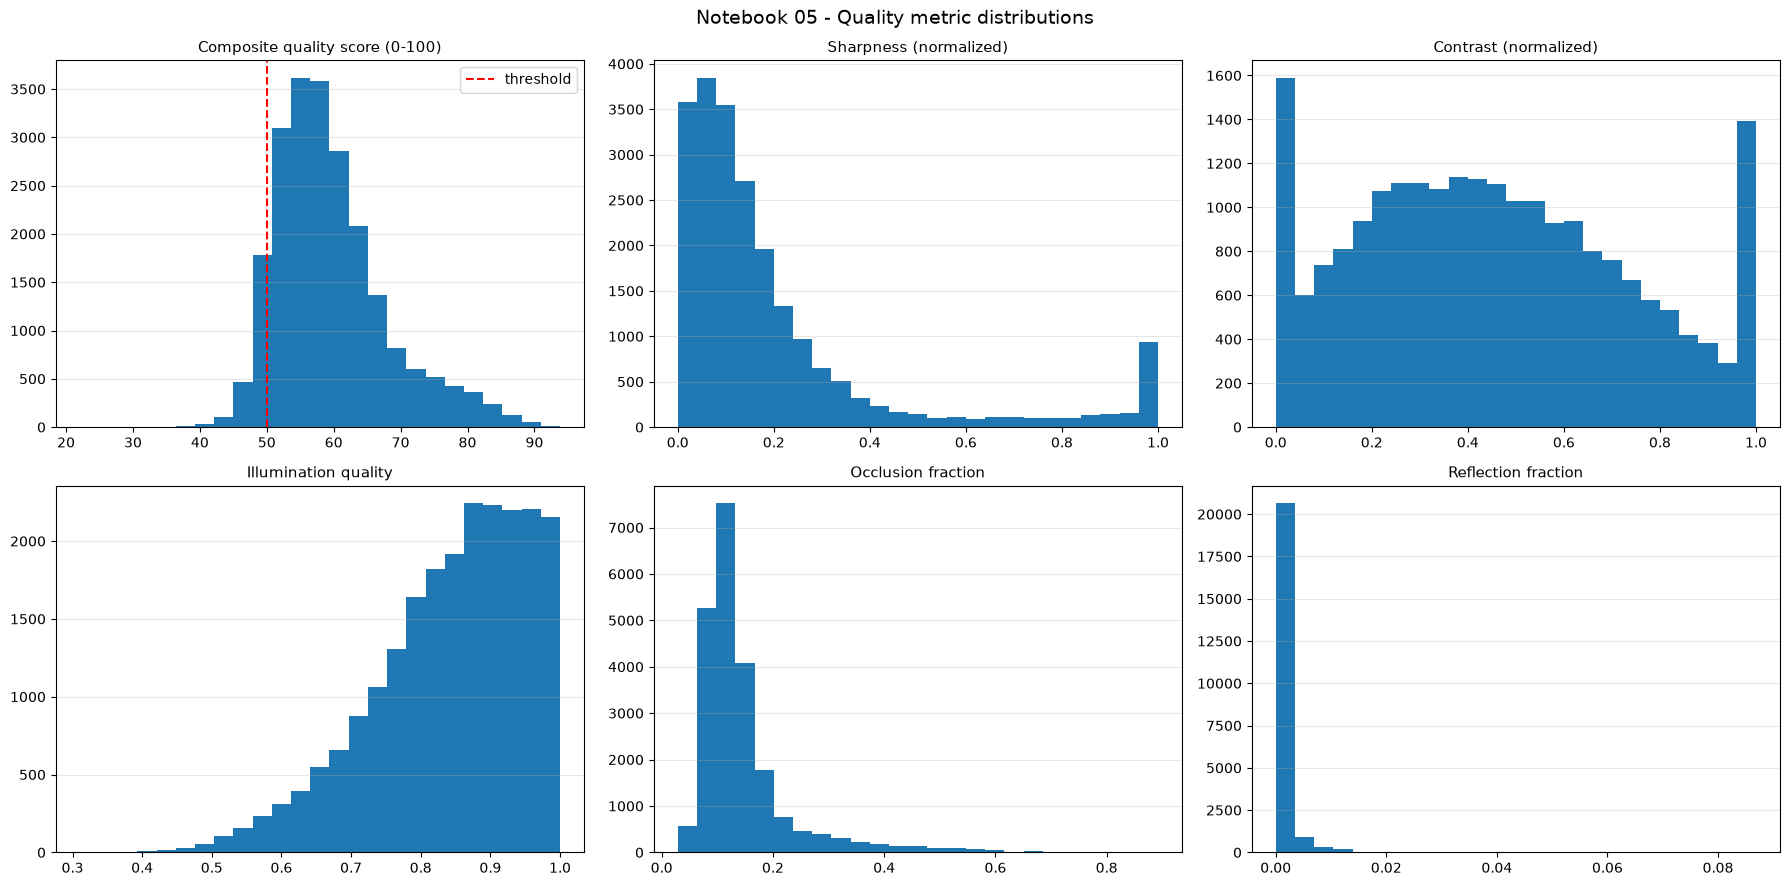

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment\quality_distributions.png


In [18]:
# ============================================================
# 19. Plot quality score and metric distributions
# ============================================================

scored_only = quality_scores[quality_scores["success"] == True]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

plot_fields = [
    ("quality_score", "Composite quality score (0-100)"),
    ("sharpness_norm", "Sharpness (normalized)"),
    ("contrast_norm", "Contrast (normalized)"),
    ("illumination_quality", "Illumination quality"),
    ("occlusion_fraction", "Occlusion fraction"),
    ("reflection_fraction", "Reflection fraction"),
]

for ax, (field, title) in zip(axes, plot_fields):
    values = scored_only[field].dropna()
    if len(values):
        ax.hist(values, bins=25, color="tab:blue")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=0.3)

axes[0].axvline(QUALITY_THRESHOLD, color="red", linestyle="--", label="threshold")
axes[0].legend()

plt.suptitle("Notebook 05 - Quality metric distributions", fontsize=14)
plt.tight_layout()

distribution_plot_path = RESULTS_DIR / "quality_distributions.png"

plt.savefig(
    distribution_plot_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", distribution_plot_path)

In [19]:
# ============================================================
# 20. Output verification
# ============================================================

def path_exists(path_value):
    '''Safely check whether a stored file path exists.'''

    if pd.isna(path_value):
        return False

    if not isinstance(path_value, (str, Path)):
        return False

    if isinstance(path_value, str) and not path_value.strip():
        return False

    return Path(path_value).exists()


copied_check = quality_scores.loc[
    quality_scores["success"] == True,
    "output_path",
].apply(path_exists)

print("Fraction of scored images with a verified output_path on disk:")
print(f"{copied_check.mean() * 100:.2f}%" if len(copied_check) else "N/A")

Fraction of scored images with a verified output_path on disk:
100.00%


In [21]:
# ============================================================
# 21. Final output verification
# ============================================================

print("Notebook 05 output directory:")
print(RESULTS_DIR)

print("\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print("\nAcceptance rate:")
scored = quality_scores["success"]
print(
    f"{quality_scores.loc[scored, 'accepted'].mean() * 100:.2f}%"
    if scored.sum()
    else "N/A"
)

print("\nNotebook 05 completed.")

Notebook 05 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment

Top-level generated files:
- quality_distributions.png
- quality_rejections.csv
- quality_scores.csv
- quality_summary_by_dataset.csv

Acceptance rate:
91.90%

Notebook 05 completed.


## 22. What this notebook hands to Notebook 06

Notebook 06 builds the **few-shot dataset** (1-shot, 2-shot, 3-shot, 5-shot) by sampling support images per identity.

The expected hand-off is:

```text
Notebook 04                 Notebook 05                    Notebook 06
Enhanced iris texture --->  Quality scoring + filtering --->  Few-shot support/query
                             good_images/ / bad_images/         split creation
```

Notebook 06 should draw its support and query samples **only from `good_images/`** (equivalently, rows in `quality_scores.csv` with `accepted == True`), since a few-shot support set is especially sensitive to any single low-quality sample. `bad_images/` and the rejected rows in `quality_scores.csv` are kept for transparency and error analysis, not as a source of training samples.
